Step 1 - Importing the Required Libraries. Mounting Google Drive for Ease of Access to Database

In [11]:
%matplotlib inline
%config InlineBackend.figure_format='retina'

import matplotlib.pyplot as plt

import torch
from torch import nn, optim
import torch.nn.functional as F
from torchvision import datasets, transforms, models
from torch.utils.data.sampler import SubsetRandomSampler

import numpy as np

from tqdm import tqdm

from google.colab import drive
drive.mount("/content/gdrive")

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


Step 2 - Getting the Data from Google Drive. Splitting the Data into Train, Test and Validation

In [12]:
num_workers=0 # Number of Subprocesses to Use for Data Loading
batch_size=20 # How Many Samples Per Batch to Load
valid_size=0.2 # Percentage of Training Set to Use as Validation

data_dir = '/content/gdrive/My Drive/reCAPTCHA_Dataset'

# Augment the Data, Convert it to a Normalized torch.FloatTensor and Resize it
transform=transforms.Compose([transforms.RandomHorizontalFlip(), transforms.RandomRotation(10), transforms.ToTensor(), transforms.Resize((120, 120)), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) ])

full_dataset=datasets.ImageFolder(data_dir, transform=transform) # Get the Entire Dataset

# Splitting the Full Dataset into Training and Testing Sets
train_size=int(0.9*len(full_dataset))
test_size=len(full_dataset)-train_size
train_dataset, test_dataset=torch.utils.data.random_split(full_dataset, [train_size, test_size])

# Obtain Training Indices that will be Used for Validation
num_train=len(train_dataset)
indices=list(range(num_train))
np.random.shuffle(indices)
split=int(np.floor(valid_size*num_train))
train_idx, valid_idx=indices[split:], indices[:split]

# Define Samplers for Obtaining Training and Validation Batches
train_sampler=SubsetRandomSampler(train_idx)
valid_sampler=SubsetRandomSampler(valid_idx)

# Prepare Data Loaders (Combine Dataset and Sampler)
train_loader=torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, sampler=train_sampler, num_workers=num_workers)
valid_loader=torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, sampler=valid_sampler, num_workers=num_workers)
test_loader=torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=True)

classes = ['Bicycle', 'Bridge', 'Bus', 'Car', 'Traffic Light'] # Specify the Image Classes

Step 3 - Visualise the Training Data

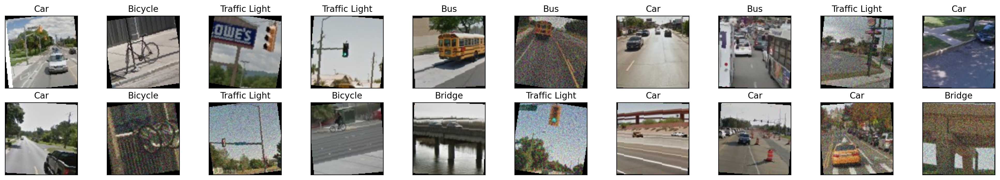

In [13]:
def imshow(img): # Function to Un-Normalize and Display an Image
    img=img/2+0.5  # Un-Normalize
    plt.imshow(np.transpose(img, (1, 2, 0)))  # Convert from Tensor Image

# Obtain One Batch of Training Images
for image, label in train_loader:
    images, labels=image, label
    break
images=images.numpy() # Convert Images to numpy for Display

fig=plt.figure(figsize=(25, 4)) # Plot the Images in the Batch along with the Corresponding Labels

# Display 20 Images
for idx in np.arange(20):
    ax=fig.add_subplot(2, 20//2, idx+1, xticks=[], yticks=[])
    imshow(images[idx])
    ax.set_title(classes[labels[idx]])

Step 4 - How Computers View Images

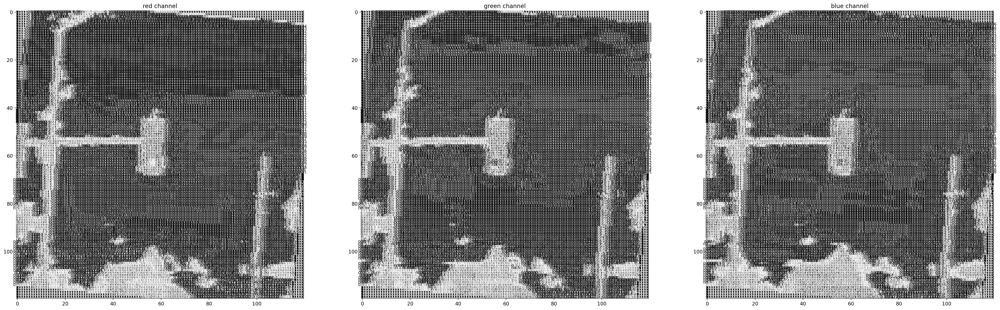

In [14]:
rgb_img=np.squeeze(images[3])
channels=['red channel', 'green channel', 'blue channel']

fig=plt.figure(figsize=(36, 36))
for idx in np.arange(rgb_img.shape[0]):
    ax=fig.add_subplot(1, 3, idx + 1)
    img=rgb_img[idx]
    ax.imshow(img, cmap='gray')
    ax.set_title(channels[idx])
    width, height=img.shape
    thresh=img.max()/2.5
    for x in range(width):
        for y in range(height):
            val=round(img[x][y],2) if img[x][y] !=0 else 0
            ax.annotate(str(val), xy=(y,x), horizontalalignment='center', verticalalignment='center', size=8, color='white' if img[x][y]<thresh else 'black')

Step 5 - Use GPU if Available or Else Use CPU and Get the Pre-Trained VGG16 Model

In [15]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu") # Use GPU if it's Available

model=models.vgg16(pretrained=True) # Get the Pre-Trained VGG16 Model from torchvision.models
print(model) # Print the Architecture

/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

Step 6 - Freeze Parameters, Create a New Classifier, Define Our Loss Function & Optimizer and Move the Model to Device

In [16]:
# Freeze Parameters so we don't Backprop through them which Speeds Up the Training Time
for param in model.parameters():
    param.requires_grad=False

# We Need to Create a New Classifier because we only have 5 Output Features
model.classifier=nn.Sequential(nn.Linear(25088, 4096), nn.ReLU(), nn.Dropout(0.5), nn.Linear(4096, 4096), nn.ReLU(), nn.Dropout(0.5), nn.Linear(4096, 1000), nn.ReLU(), nn.Dropout(0.5), nn.Linear(1000, 5))

criterion=nn.CrossEntropyLoss() # Defining Our Loss Function
optimizer=optim.Adam(model.classifier.parameters(), lr=0.0005) # Defining Our Optimizer

model.to(device); # Move Model to Device

Step 7 - Train the Model

In [22]:
n_epochs=25 # Number of Epochs to Train the Model

valid_loss_min=np.Inf # Track Changes in Validation Loss

for epoch in range(1, n_epochs+1):

    # Keep Track of Training and Validation Loss
    train_loss=0.0
    valid_loss=0.0

    # Train the Model
    model.train()
    loop=tqdm(enumerate(train_loader), total=len(train_loader), position=0, leave=False)
    for batch_idx, (data, target) in loop:
        data, target=data.to(device), target.to(device) # Move Tensors to GPU if CUDA is Available
        optimizer.zero_grad() # Clear the Gradients
        output=model(data) # Forward Pass: Compute Predicted Outputs by Passing Inputs to the Model
        loss=criterion(output, target) # Calculate the Batch Loss
        loss.backward() # Backward Pass: Compute Gradient of the Loss with respect to Model Parameters
        optimizer.step() # Perform a Single Optimization Step (Parameter Update)
        train_loss+=loss.item()*data.size(0) # Update Training Loss
        # Update Progress Bar
        loop.set_description(f"Epoch [{epoch}/{n_epochs}]")
        loop.set_postfix(loss = loss.item())

    # Validate the Model
    model.eval()
    for batch_idx, (data, target) in enumerate(valid_loader):
        data, target=data.to(device), target.to(device) # Move Tensors to GPU if CUDA is Available
        output=model.forward(data) # Forward Pass: Compute Predicted Outputs by Passing Inputs to the Model
        loss=criterion(output, target) # Calculate the Batch Loss
        valid_loss+=loss.item()*data.size(0) # Update Average Validation Loss

    # Calculate Average Losses
    train_loss=train_loss/len(train_loader.sampler)
    valid_loss=valid_loss/len(valid_loader.sampler)

    # Print Training and Validation Statistics
    print('Epoch: {} \tTraining Loss: {:.6f} \tValidation Loss: {:.6f}'.format(epoch, train_loss, valid_loss))

    # Save Model if Validation Loss has Decreased
    if (valid_loss<=valid_loss_min):
        print('Validation loss decreased ({:.6f} --> {:.6f}).  Saving model ...'.format(valid_loss_min, valid_loss))
        torch.save(model.state_dict(), 'model_augmented.pt')
        valid_loss_min=valid_loss

Epoch: 1 	Training Loss: 0.501757 	Validation Loss: 0.726181
Validation loss decreased (inf --> 0.726181).  Saving model ...


Epoch: 2 	Training Loss: 0.536952 	Validation Loss: 0.836917


Epoch: 3 	Training Loss: 0.497296 	Validation Loss: 0.674869
Validation loss decreased (0.726181 --> 0.674869).  Saving model ...


Epoch: 4 	Training Loss: 0.483288 	Validation Loss: 0.635171
Validation loss decreased (0.674869 --> 0.635171).  Saving model ...


Epoch: 5 	Training Loss: 0.516094 	Validation Loss: 0.733920


Epoch: 6 	Training Loss: 0.482611 	Validation Loss: 0.625958
Validation loss decreased (0.635171 --> 0.625958).  Saving model ...


... (15 outputs left out)

Epoch: 22 	Training Loss: 0.369167 	Validation Loss: 0.789315


Epoch: 23 	Training Loss: 0.381061 	Validation Loss: 0.814868


Epoch: 24 	Training Loss: 0.350464 	Validation Loss: 0.842265


Epoch: 25 	Training Loss: 0.346919 	Validation Loss: 0.745782


Step 8 - Load the Model with the Lowest Validation Loss and Store it in Permanent Storage like Drive for Future Use

In [25]:
model.load_state_dict(torch.load('model_augmented.pt'))

torch.save(model.state_dict(), '/content/gdrive/My Drive/reCAPTCHA_Solver.pth')
# model.load_state_dict(torch.load('/content/gdrive/My Drive/reCAPTCHA_Solver.pth'))

torch.save(model.state_dict(), 'reCAPTCHA_Solver.pth')
# model.load_state_dict(torch.load('reCAPTCHA_Solver.pth'))

Step 9 - Test the Model

In [26]:
# Track Test Loss
test_loss=0.0
class_correct=list(0. for i in range(5))
class_total=list(0. for i in range(5))

model.eval()
# Iterate over Test Data
for batch_idx, (data, target) in enumerate(test_loader):
    data, target=data.to(device), target.to(device) # Move Tensors to GPU if CUDA is Available
    output=model(data) # Forward Pass: Compute Predicted Outputs by Passing Inputs to the Model
    loss=criterion(output, target) # Calculate the Batch Loss
    test_loss+=loss.item()*data.size(0) # Update Test Loss
    _, pred=torch.max(output, 1) # Convert Output Probabilities to Predicted Class
    correct_tensor=pred.eq(target.data.view_as(pred)) # Compare Predictions to Ground Truth
    correct=np.squeeze(correct_tensor.cpu().numpy()) if not device == "cuda" else np.squeeze(correct_tensor.cpu().numpy())
    # Calculate Test Accuracy for each Object Class
    for i in range(batch_size):
        label=target.data[i]
        class_correct[label]+=correct[i].item()
        class_total[label]+=1

# Average Test Loss
test_loss=test_loss/len(test_loader.dataset)
print('Test Loss: {:.6f}\n'.format(test_loss))

for i in range(5):
    if(class_total[i]>0):
        print('Test Accuracy of %5s: %2d%% (%2d/%2d)' % (classes[i], 100*class_correct[i]/class_total[i], np.sum(class_correct[i]), np.sum(class_total[i])))
    else:
        print('Test Accuracy of %5s: N/A (no training examples)' % (classes[i]))

print('\nTest Accuracy (Overall): %2d%% (%2d/%2d)' % (100.*np.sum(class_correct)/np.sum(class_total), np.sum(class_correct), np.sum(class_total)))

Test Loss: 0.520594

Test Accuracy of Bicycle: 92% (76/82)
Test Accuracy of Bridge: 81% (56/69)
Test Accuracy of   Bus: 78% (80/102)
Test Accuracy of   Car: 75% (72/95)
Test Accuracy of Traffic Light: 76% (55/72)

Test Accuracy (Overall): 80% (339/420)


Step 10 - Visualise Test Sample Results

[3 3 2 3 4 1 3 2 0 0 2 3 4 4 2 3 0 1 4 2]


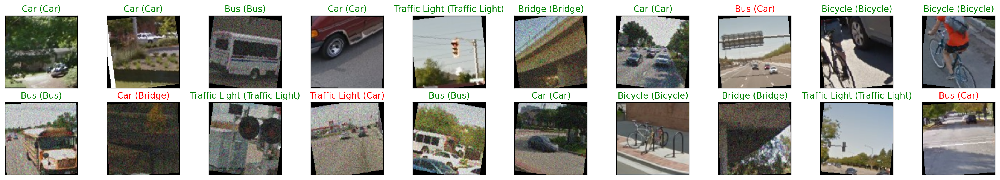

In [27]:
# Obtain One Batch of Test Images
for image, label in test_loader:
    images, labels=image, label
    break
images.numpy()

images=images.to(device) # Move Model Inputs to cuda, if GPU is Available

output=model(images) # Get Sample Outputs

_, preds_tensor=torch.max(output, 1) # Convert Output Probabilities to Predicted Class
preds=np.squeeze(preds_tensor.cpu().numpy()) if not device == "cuda" else np.squeeze(preds_tensor.cpu().numpy())
print(preds)

images=images.cpu().numpy() # Move Images to CPU and Convert to numpy Array

# Plot the Images in the Batch along with Predicted and True Labels
fig=plt.figure(figsize=(25, 4))
for idx in np.arange(20):
    ax=fig.add_subplot(2, 10, idx+1, xticks=[], yticks=[])
    imshow(images[idx])
    ax.set_title("{} ({})".format(classes[preds[idx]], classes[labels[idx]]), color=("green" if preds[idx]==labels[idx].item() else "red"))